
# COU 07506 Digital Signal Processing — Week 2: Sampling, Aliasing and Quantization

**Name:** Victoria Bintu Birhanenwa

**Registration No.:** 25024592742

**Class:** BENG24COE

**Date:** 22 November 2026


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 4)

print("Week 2 DSP environment is ready!")


Week 2 DSP environment is ready!



## Pre-Lab Questions

### Question 1
A 7 kHz tone is sampled at 10 kHz. What frequency will appear in the sampled signal?

**Answer:**

The Nyquist frequency is:

\[
f_N = \frac{f_s}{2} = \frac{10}{2} = 5\text{ kHz}
\]

Since the original frequency (7 kHz) is higher than the Nyquist frequency (5 kHz), aliasing occurs.

The apparent frequency is:

\[
f_{alias} = |7 - 10| = 3\text{ kHz}
\]

Therefore, the frequency that appears is **3 kHz**.

### Question 2
Calculate the quantization step size (Δ) and theoretical SQNR for an 8-bit quantizer with a ±1 V range.

**Answer:**

Given:

- Number of bits, B = 8
- Maximum amplitude, Xm = 1 V

The quantization step size is:

\[
\Delta = \frac{2X_m}{2^B}
\]

\[
\Delta = \frac{2(1)}{2^8}
= \frac{2}{256}
= 0.0078125\text{ V}
\]

The theoretical SQNR is:

\[
SQNR = 6.02B + 1.76
\]

\[
SQNR = 6.02(8) + 1.76
= 49.92\text{ dB}
\]

Therefore:

- **Quantization step size:** 0.0078125 V
- **Theoretical SQNR:** 49.92 dB


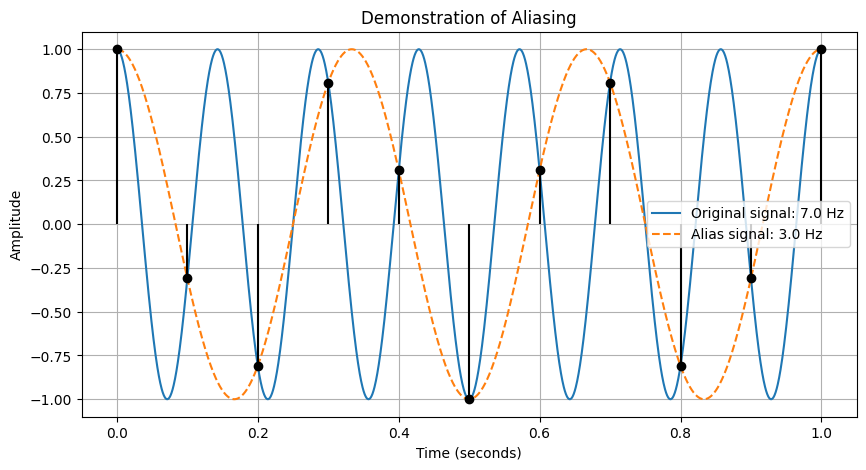

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Alias frequency: 3.0 Hz


In [ ]:

# Task 2.1: Aliasing of a Sinusoid

f0 = 7.0
fs = 10.0

# Create a dense time axis to represent the original signal
t = np.linspace(0, 1, 2000)

# Create sampling points
n = np.arange(0, int(fs) + 1)
tn = n / fs

# Calculate alias frequency
f_alias = abs(f0 - fs * round(f0 / fs))

# Plot original signal, alias signal and sampled points
plt.figure(figsize=(10, 5))

plt.plot(t, np.cos(2 * np.pi * f0 * t),
         label=f"Original signal: {f0} Hz")

plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--",
         label=f"Alias signal: {f_alias} Hz")

plt.stem(tn, np.cos(2 * np.pi * f0 * tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Demonstration of Aliasing")
plt.legend()
plt.grid()
plt.show()

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Alias frequency:", f_alias, "Hz")


In [ ]:

# Task 2.1: Testing different sampling frequencies

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

print("Aliasing Results")
print("-----------------------------")

for fs in sampling_rates:
    f_alias = abs(f0 - fs * round(f0 / fs))

    print("Sampling frequency:", fs, "Hz",
          "| Alias frequency:", f_alias, "Hz")


Aliasing Results
-----------------------------
Sampling frequency: 10 Hz | Alias frequency: 3.0 Hz
Sampling frequency: 12 Hz | Alias frequency: 5.0 Hz
Sampling frequency: 14 Hz | Alias frequency: 7.0 Hz
Sampling frequency: 20 Hz | Alias frequency: 7.0 Hz



### Task 2.1: Results and Discussion

The original sinusoidal signal has a frequency of 7 Hz. Different sampling frequencies were used to observe aliasing.

| Sampling Frequency (Hz) | Nyquist Frequency (Hz) | Alias Frequency (Hz) | Observation |
|---:|---:|---:|---|
| 10 | 5 | 3 | Aliasing occurs |
| 12 | 6 | 5 | Aliasing occurs |
| 14 | 7 | 7 | Nyquist boundary |
| 20 | 10 | 7 | No aliasing |

**Discussion:**

Aliasing occurs when a signal is sampled below twice its highest frequency. When the sampling frequency is insufficient, higher-frequency signals appear as lower-frequency signals.

The experiment demonstrated that increasing the sampling frequency reduces aliasing. At 20 Hz, the sampling frequency is sufficient to represent the 7 Hz signal without aliasing.


 TASK 2.2 — HEARING ALIASING

In [ ]:

# Check whether FFmpeg is available
!ffmpeg -version


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --enable-

In [1]:

!ffmpeg -i "Voice signal.wav" -ar 16000 -ac 1 -sample_fmt s16 my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [3]:
from scipy.io import wavfile
import numpy as np

print("Imports restored successfully!")

Imports restored successfully!


In [4]:
fs_voice, x_voice = wavfile.read("my_voice.wav")

x_voice = x_voice.astype(float)

if np.max(np.abs(x_voice)) > 0:
    x_voice = x_voice / np.max(np.abs(x_voice))

duration = len(x_voice) / fs_voice

print("Sampling frequency:", fs_voice, "Hz")
print("Number of samples:", len(x_voice))
print("Duration:", round(duration, 2), "seconds")
print("Audio loaded successfully!")

Sampling frequency: 16000 Hz
Number of samples: 83627
Duration: 5.23 seconds
Audio loaded successfully!


In [6]:
from scipy import signal
from IPython.display import Audio, display

print("Signal processing tools loaded successfully!")

Signal processing tools loaded successfully!


In [7]:

# Task 2.2: Comparing downsampling methods

for k in [2, 4, 8]:

    # Naive downsampling (without filtering)
    naive = x_voice[::k]

    # Proper downsampling (with anti-aliasing filter)
    proper = signal.decimate(x_voice, k, ftype="fir")

    new_fs = fs_voice // k

    print("\nReduction factor:", k)
    print("New sampling frequency:", new_fs, "Hz")

    print("Naive downsampling:")
    display(Audio(naive, rate=new_fs))

    print("Proper downsampling:")
    display(Audio(proper, rate=new_fs))



Reduction factor: 2
New sampling frequency: 8000 Hz
Naive downsampling:


Proper downsampling:



Reduction factor: 4
New sampling frequency: 4000 Hz
Naive downsampling:


Proper downsampling:



Reduction factor: 8
New sampling frequency: 2000 Hz
Naive downsampling:


Proper downsampling:



### Task 2.2: Hearing Aliasing

**Observations:**

The original voice recording was sampled at 16,000 Hz. It was downsampled using reduction factors of 2, 4 and 8.

Two methods were compared:

1. Naive downsampling, which reduces the samples without applying a filter.
2. Proper downsampling, which applies a low-pass anti-aliasing filter before reducing the samples.

The naive downsampled audio showed more distortion compared to the properly filtered audio.

**Conclusion:**

Anti-aliasing filters are important because they remove unwanted high-frequency components before downsampling. This helps prevent aliasing and preserves the quality of the audio signal.


TASK 2.3 — UNIFORM QUANTIZER

In [8]:

# Task 2.3: Uniform Quantizer

def quantize(x, bits, full_scale=1.0):

    # Calculate quantization step size
    delta = 2 * full_scale / (2 ** bits)

    # Round samples to the nearest quantization level
    q = np.round(x / delta) * delta

    # Limit values to the allowed range
    q = np.clip(q, -full_scale, full_scale - delta)

    return q

print("Uniform quantizer function created successfully!")


Uniform quantizer function created successfully!


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

print("All required libraries imported successfully!")

All required libraries imported successfully!


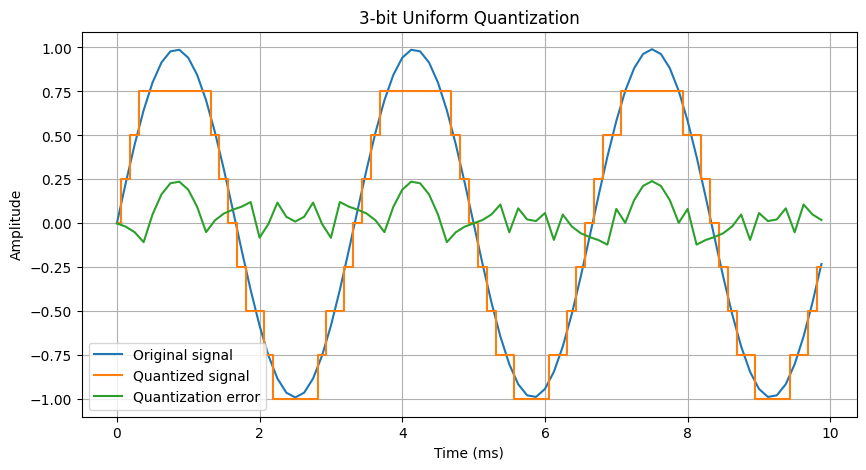

In [11]:

# Generate a 300 Hz sine wave

fs = 8000
t = np.arange(0, 0.01, 1/fs)

x_sine = 0.99 * np.sin(2 * np.pi * 300 * t)

# Apply a 3-bit quantizer
xq = quantize(x_sine, 3)

# Calculate quantization error
error = x_sine - xq

# Plot the results
plt.figure(figsize=(10, 5))

plt.plot(t * 1000, x_sine, label="Original signal")
plt.step(t * 1000, xq, where="mid", label="Quantized signal")
plt.plot(t * 1000, error, label="Quantization error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("3-bit Uniform Quantization")
plt.legend()
plt.grid()
plt.show()


In [12]:
bits = 3
full_scale = 1.0

delta = (2 * full_scale) / (2 ** bits)

print("Number of quantization levels:", 2 ** bits)
print("Quantization step size:", delta)

Number of quantization levels: 8
Quantization step size: 0.25



**Observation:**

A 3-bit uniform quantizer was implemented using Python. The quantizer produced 8 discrete amplitude levels because 2³ = 8.

The quantization step size was calculated as 0.25 V. The graph showed that the original smooth sine wave was converted into discrete amplitude levels. The difference between the original and quantized signals represents quantization error.


TASK 2.4 — VERIFY THE 6 dB-per-bit Rule

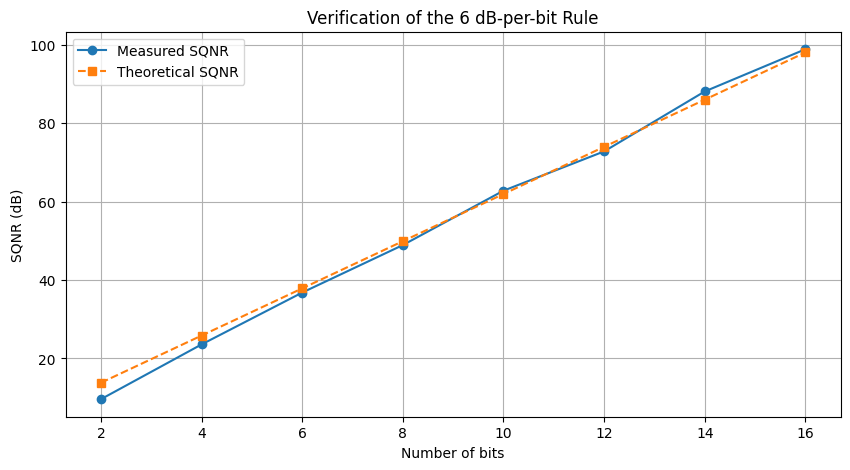

In [13]:

# Task 2.4: Verify the 6 dB-per-bit rule

bits = np.arange(2, 17, 2)

measured_sqnr = []

for B in bits:

    # Quantize the original sine wave
    x_quantized = quantize(x_sine, B)

    # Calculate signal power
    signal_power = np.sum(x_sine ** 2)

    # Calculate quantization noise power
    noise_power = np.sum((x_sine - x_quantized) ** 2)

    # Calculate SQNR in decibels
    sqnr = 10 * np.log10(signal_power / noise_power)

    measured_sqnr.append(sqnr)

# Calculate theoretical SQNR
theoretical_sqnr = 6.02 * bits + 1.76

# Plot results
plt.figure(figsize=(10, 5))

plt.plot(bits, measured_sqnr, "o-", label="Measured SQNR")
plt.plot(bits, theoretical_sqnr, "s--", label="Theoretical SQNR")

plt.xlabel("Number of bits")
plt.ylabel("SQNR (dB)")
plt.title("Verification of the 6 dB-per-bit Rule")
plt.legend()
plt.grid()
plt.show()



### Task 2.4: Verification of the 6 dB-per-bit Rule

**Observations:**

The experiment was performed using different quantization bit depths ranging from 2 to 16 bits.

The graph showed that SQNR increases as the number of quantization bits increases. The measured SQNR generally follows the theoretical SQNR curve.

**Discussion:**

Increasing the number of bits increases the number of available quantization levels. This reduces quantization error and improves the quality of the digital signal.

According to the theoretical relationship, every additional bit increases SQNR by approximately 6.02 dB.

**Conclusion:**

The experiment verified the 6 dB-per-bit rule. Higher bit resolution produces better signal quality and lower quantization noise.


TASK 2.5 — QUANTIZE YOUR VOICE RECORDING

In [14]:

# Task 2.5: Quantization of voice recording

voice_bits = [4, 8, 12]

quantized_voices = {}

for B in voice_bits:

    # Quantize the voice recording
    xq_voice = quantize(x_voice, B)

    quantized_voices[B] = xq_voice

    # Calculate SQNR
    signal_power = np.sum(x_voice ** 2)
    noise_power = np.sum((x_voice - xq_voice) ** 2)

    sqnr = 10 * np.log10(signal_power / noise_power)

    print(f"\nQuantization bits: {B}")
    print(f"SQNR: {sqnr:.2f} dB")



Quantization bits: 4
SQNR: 8.14 dB

Quantization bits: 8
SQNR: 31.57 dB

Quantization bits: 12
SQNR: 55.61 dB


In [15]:

# Listen to quantized voice recordings

for B in voice_bits:

    print(f"\nListening to {B}-bit quantized voice:")

    display(Audio(quantized_voices[B], rate=fs_voice))



Listening to 4-bit quantized voice:



Listening to 8-bit quantized voice:



Listening to 12-bit quantized voice:



### Task 2.5: Quantization of Voice Recording

**Observations:**

The voice recording was quantized using 4-bit, 8-bit and 12-bit quantizers.

Different audio qualities were observed when listening to the quantized recordings.

- 4-bit quantization produced more noticeable distortion and noise.
- 8-bit quantization provided improved audio quality.
- 12-bit quantization produced clearer audio, closer to the original recording.

The SQNR values showed how the signal quality changed with increasing bit depth.

**Conclusion:**

Increasing the number of quantization bits reduces quantization error and improves audio quality. Higher bit-depth quantization provides a more accurate representation of the original voice signal.



## Analysis Questions

### Question 1
Explain with a frequency-axis sketch why a 7 Hz tone appears at 3 Hz when sampled at 10 Hz.

**Answer:**

The sampling frequency is 10 Hz, giving a Nyquist frequency of 5 Hz.

Since the original signal frequency of 7 Hz is above the Nyquist frequency, aliasing occurs.

The apparent frequency is:

\[
f_{alias}=|7-10|=3\text{ Hz}
\]

Therefore, the 7 Hz signal appears as a 3 Hz signal after sampling.

### Question 2
In Task 2.2, why can aliasing in the naive version not be removed afterwards?

**Answer:**

Aliasing cannot easily be removed after naive downsampling because high-frequency components have already folded into lower frequencies. The original and aliased components become indistinguishable, resulting in information loss.

### Question 3
By how much does SQNR change when one bit is added?

**Answer:**

According to the theoretical relationship:

\[
SQNR=6.02B+1.76
\]

Adding one bit increases SQNR by approximately 6.02 dB. This reduces quantization noise and improves signal quality.

### Question 4
A temperature sensor changes by a maximum of 0.1 °C/s and requires a resolution of 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits.

**Answer:**

A suitable sampling rate is 10 samples per second (10 Hz).

The maximum temperature change between samples will be:

\[
\frac{0.1}{10}=0.01^\circ C
\]

The number of bits required is:

\[
2^B \geq \frac{100}{0.01}
\]

\[
2^B \geq 10000
\]

\[
B \geq \log_2(10000)
\]

\[
B \geq 13.29
\]

Therefore, 14 bits are required.

A 14-bit quantizer provides 16,384 levels, giving a resolution of approximately:

\[
\frac{100}{16384}=0.0061^\circ C
\]

This satisfies the required resolution of 0.01 °C.






ChatGPT was used as a learning assistant to help explain digital signal processing concepts, guide Python implementation, troubleshoot errors and understand experimental results. All practical experiments were executed and reviewed by the student.
